In [72]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the CSV file
df = pd.read_csv("cache_results.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Remove any formatting artifacts, if present
df.columns = df.columns.str.replace("*", "", regex=False)

# Convert numeric columns to numbers
numeric_cols = [
    "cache_size_KB",
    "hits",
    "misses",
    "writes"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with invalid values
df = df.dropna(subset=numeric_cols)


# Group by cache type and cache size.
# Sum repeated results for the same configuration.
# grouped = df.groupby(["name","associativity","replacement_policy","write_policy","cache_size_KB","line_size","blocks","sets" ])[
#     ["hits", "misses", "writes"]
# ].sum().reset_index()
grouped = df



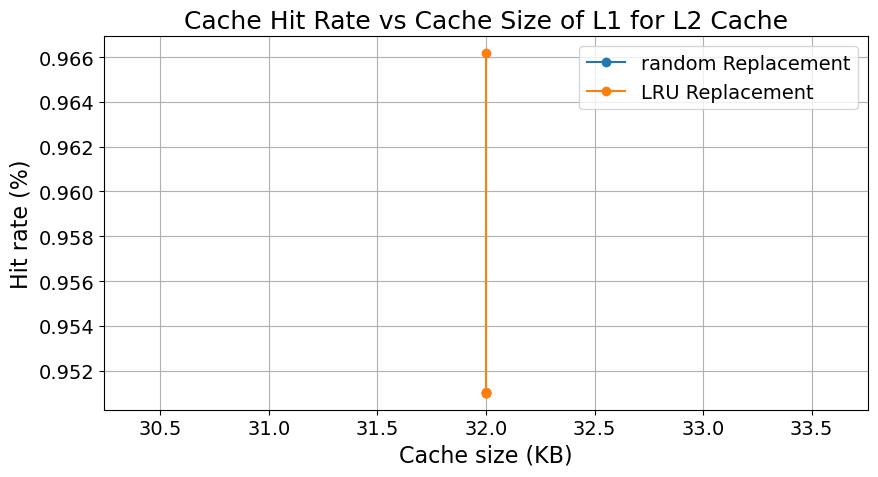

,name,associativity,replacement_policy,write_policy,cache_size_KB,line_size,blocks,sets,hits,misses,writes,hit_rate,miss_rate,write_rate


In [73]:
# Calculate hit and miss rates
grouped["hit_rate"] = (
    grouped["hits"] /
    (grouped["hits"] + grouped["misses"])
)

grouped["miss_rate"] = (
    grouped["misses"] /
    (grouped["hits"] + grouped["misses"])
)

grouped["write_rate"] = (
    grouped["writes"] /
    (grouped["hits"] + grouped["misses"])
)

# Plot 1: Hit rate vs cache size
plt.figure(figsize=(9, 5))
name = "L1 Data cache"
name_y = "L2 Unified cache"

data = grouped[ (grouped["name"] == name) & 
                (grouped["write_policy"] == "write-back")&
                (grouped["replacement_policy"] == "random")]
data = data.sort_values("cache_size_KB")
data2 = 0

data_y = grouped[(grouped["name"] == name_y) & 
                (grouped["write_policy"] == "write-back")&
                (grouped["replacement_policy"] == "random")]

data2 = grouped[ (grouped["name"] == name) & 
                (grouped["write_policy"] == "write-back")&
                (grouped["replacement_policy"] == "LRU")]

data2_y = grouped[ (grouped["name"] == name_y) & 
                (grouped["write_policy"] == "write-back")&
                (grouped["replacement_policy"] == "LRU")]
# data2=0
data2 = data2.sort_values("cache_size_KB")
plt.plot(
        data["cache_size_KB"],
        data_y["hit_rate"],
        marker="o",
        label="random Replacement"
    )

plt.plot(
        data2["cache_size_KB"],
        data2_y["hit_rate"],
        marker="o",
        label="LRU Replacement"
    )
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 20
})
plt.xlabel("Cache size (KB)")
plt.ylabel("Hit rate (%)")
plt.title("Cache Hit Rate vs Cache Size of L1 for L2 Cache")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

data


In [102]:
# df[df["write_policy"] == "write-back"].groupby("cache_size_KB")["writes"].mean().plot(label="write-back")
df = pd.read_csv("cache_results.csv")
df["write_rate"] = (
    df["writes"] /
    (df["hits"] + df["misses"])
)
df["hit_rate"] = (
    df["hits"] /
    (df["hits"] + df["misses"])
)
df[df["name"]=="L2 Unified cache"]
# df[df["name"]=="L1 Data cache"]

,name,associativity,replacement_policy,write_policy,cache_size_KB,line_size,blocks,sets,hits,misses,writes,write_rate,hit_rate
2,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,5604189,387470,1850856,0.308905,0.935332
5,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,5761886,229773,1850856,0.308905,0.961651
8,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,2702802,293029,925428,0.308905,0.902188
11,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,1989443,259642,695096,0.309057,0.884557
14,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,1099430,400698,463739,0.309133,0.732891
17,L2 Unified cache,8-way,LRU,write-back,512.0,64,8192,1024,899639,236281,349099,0.307327,0.791992
20,L2 Unified cache,8-way,LRU,write-back,512.0,4,131072,16384,1012719,487409,463739,0.309133,0.675088
23,L2 Unified cache,8-way,LRU,write-back,512.0,8,65536,8192,1044723,455405,463739,0.309133,0.696423
26,L2 Unified cache,8-way,LRU,write-back,512.0,16,32768,4096,1013518,486610,463739,0.309133,0.675621
29,L2 Unified cache,8-way,LRU,write-back,512.0,32,16384,2048,1239861,260267,463739,0.309133,0.826503


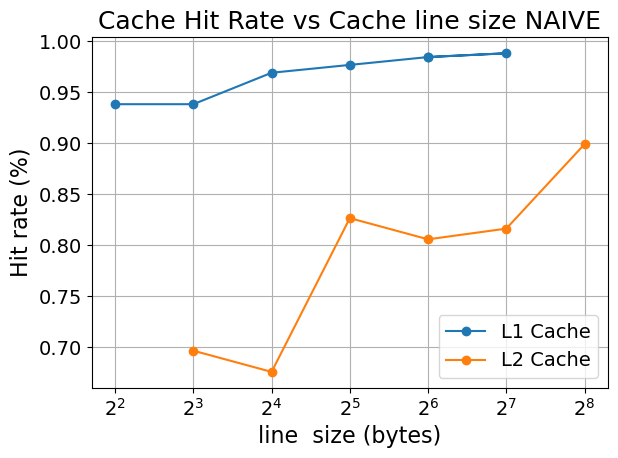

In [ ]:
#Code for block size
plt.plot(df[df["name"]=="L1 Data cache"]["line_size"][:8], df[df["name"]=="L1 Data cache"]["hit_rate"][:8],
                 marker="o",
        label="L1 Cache"
    )
plt.plot(df[df["name"]=="L2 Unified cache"]["line_size"][7:], df[df["name"]=="L2 Unified cache"]["hit_rate"][7:],
                 marker="o",
        label="L2 Cache"
    )
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 20
})
plt.xlabel("line  size (bytes)")
plt.ylabel("Hit rate (%)")
plt.title("Cache Hit Rate vs Cache line size NAIVE")
plt.legend()
plt.xscale('log', base=2)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Code for associativity
plt.plot([1, 2, 4, 6, 16], df[df["name"]=="L1 Data cache"]["hit_rate"][:5],
                 marker="o",
        label="L1 Cache"
    )
plt.plot([1, 2, 4, 6, 16], df[df["name"]=="L2 Unified cache"]["hit_rate"][5:],
                 marker="o",
        label="L2 Cache"
    )
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 20
})
plt.xlabel("Associativity (ways)")
plt.ylabel("Hit rate (%)")
plt.title("Cache Hit Rate vs Cache Associativity BLOCK")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
# 66678601+430263 + 83951871-151060737

# 17097489 + 109992
343301 + 110576 - 23951

429926